# Sudan Atlas in Python

Match messy Sudanese place names to official P-codes, then map the result.

```
pip install "sudan-atlas[geo]" matplotlib
```

The `[geo]` extra adds GeoDataFrames (via geopandas); the matcher itself needs only `sudan-atlas`.

## 1. Match names as people type them

A typical partner spreadsheet: inconsistent spellings, Arabic and English, the state in another column. The values are made-up examples.

In [1]:
import pandas as pd
from sudan_atlas import match

rows = pd.DataFrame({
    "locality": ["El Fasher", "Kutum", "الطينة", "Kalimendo", "Um Keddada", "Melit", "Tawila IDPs", "Habila"],
    "state":    ["North Darfur"] * 7 + [""],
    "people_reached": [5200, 1300, 800, 650, 1900, 700, 2400, 300],
})

results = [match(r.locality, state_hint=r.state or None, level=2) for r in rows.itertuples()]
rows["pcode"] = [r["pcode"] for r in results]
rows["matched"] = [r["name_en"] for r in results]
rows["method"] = [r["method"] for r in results]
rows["score"] = [r["score"] for r in results]
rows

,locality,state,people_reached,pcode,matched,method,score
0,El Fasher,North Darfur,5200,SD02114,Al Fasher,exact,1.00
1,Kutum,North Darfur,1300,SD02128,Kutum,exact,1.00
2,الطينة,North Darfur,800,SD02171,At Tina,exact,1.00
3,Kalimendo,North Darfur,650,SD02126,Kelemando,fuzzy,0.90
4,Um Keddada,North Darfur,1900,SD02136,Um Kadadah,fuzzy,0.90
5,Melit,North Darfur,700,SD02129,Melit,exact,1.00
6,Tawila IDPs,North Darfur,2400,SD02170,Tawila,exact,1.00
7,Habila,,300,NaN,NaN,ambiguous,0.98


Every match reports how it was found (`exact`, `variant` or `fuzzy`) and a score. The matcher never guesses: "Habila" is a locality in both West Darfur and South Kordofan, so with no state it returns no `pcode`, only alternatives.

In [2]:
[(a["pcode"], a["name_en"], a["score"]) for a in match("Habila", level=2)["alternatives"]]

[('SD04122', 'Habila - WD', 0.98),
 ('SD07103', 'Habila - SK', 0.98),
 ('SD10070', 'Haya', 0.8)]

In [3]:
match("Habila", state_hint="West Darfur", level=2)["pcode"]

'SD04122'

## 2. Look places up

In [4]:
from sudan_atlas import get_states, get_localities

print(len(get_states()), "states;", len(get_localities()), "localities")
pd.DataFrame(get_localities("SD02"))[["pcode", "name_en", "name_ar"]].head()

19 states; 189 localities


,pcode,name_en,name_ar
0,SD02113,Dar As Salam,دار السلام
1,SD02114,Al Fasher,الفاشر
2,SD02116,Al Koma,الكومة
3,SD02117,Al Malha,المالحة
4,SD02118,As Serief,السريف


## 3. Map the result

`sudan_atlas.geo` returns GeoDataFrames at `detailed`, `medium` or `light` resolution.

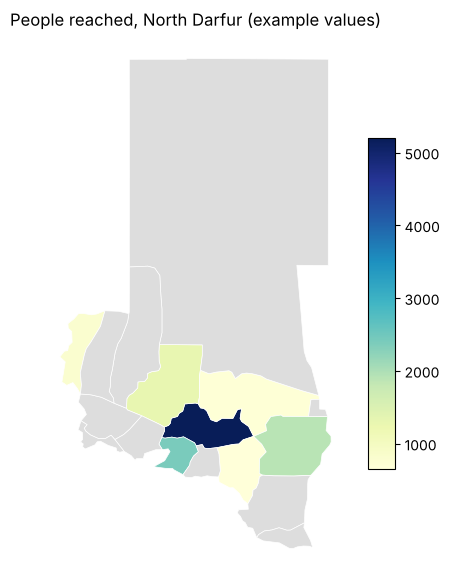

In [5]:
import matplotlib.pyplot as plt
from sudan_atlas import geo

localities = geo.localities("SD02")  # North Darfur
mapped = localities.merge(rows[["pcode", "people_reached"]], on="pcode", how="left")

ax = mapped.plot(column="people_reached", cmap="YlGnBu", legend=True, figsize=(6, 7),
                 missing_kwds={"color": "#dddddd", "label": "no data"}, edgecolor="white", linewidth=0.5)
ax.set_title("People reached, North Darfur (example values)")
ax.set_axis_off()
plt.show()

Boundaries: OCHA COD-AB Sudan (v03), CC BY 3.0 IGO. They do not imply any opinion on the legal status of any territory.